In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("dataset_09.csv", header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,41
0,0,tcp,ftp_data,SF,491.0,0.0,0.0,0.0,0.0,0.0,...,25.0,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0.0,0.0,0.0,0.0,0.0,0.0,...,26.0,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232.0,8153.0,0.0,0.0,0.0,0.0,...,255.0,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199.0,420.0,0.0,0.0,0.0,0.0,...,255.0,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [4]:
X = df.iloc[:, :-1].copy()
X.columns = X.columns.astype(str)

X = pd.get_dummies(X, columns=X.select_dtypes(include="object").columns)
X = X.fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

distances = ((X_scaled - kmeans.cluster_centers_[clusters]) ** 2).sum(axis=1) ** 0.5
threshold = pd.Series(distances).quantile(0.95)

df["Cluster"] = clusters
df["Anomaly"] = distances > threshold

print("Unusual traffic records:", df["Anomaly"].sum())
df.head()

Unusual traffic records: 918


,0,1,2,3,4,5,6,7,8,9,...,34,35,36,37,38,39,40,41,Cluster,Anomaly
0,0,tcp,ftp_data,SF,491.0,0.0,0.0,0.0,0.0,0.0,...,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0,False
1,0,udp,other,SF,146.0,0.0,0.0,0.0,0.0,0.0,...,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0,False
2,0,tcp,private,S0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,False
3,0,tcp,http,SF,232.0,8153.0,0.0,0.0,0.0,0.0,...,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0,False
4,0,tcp,http,SF,199.0,420.0,0.0,0.0,0.0,0.0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0,False


In [6]:
df["Anomaly"].value_counts().rename(index={False: "Normal", True: "Unusual"})

Anomaly
Normal     17443
Unusual      918
Name: count, dtype: int64

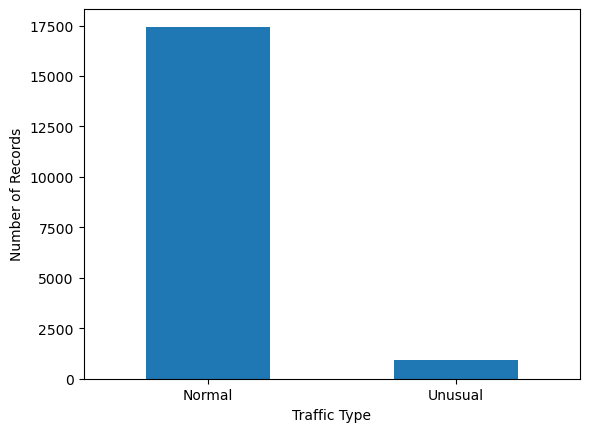

In [7]:
df["Anomaly"].value_counts().plot(kind="bar")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Normal", "Unusual"], rotation=0)
plt.show()